# **Supervised Learning Methods**
## **Classifying Breast Cancer: A Comparative Analysis**

**Authors:** Carla Bellido García, Cindy Chen, Celica Krigul, Keith Megara Osores Vicuña, Ema Štangová
  
**Master:** Health Data Science

**Subject:** Machine Learning

**Course:** 2025-2026

---

## **Table of Contents**

**1. [Overview](#section1)**   

**2. [Dataset](#section2)**  
&emsp; **2.1 [Breast Cancer Wisconsin (Diagnostic) Dataset](#section21)**     
&emsp; **2.1 [Features](#section22)**     
  
**3. [Assignment Tasks](#section3)**  
&emsp; **3.1 [Task 1 - Data Loading & Exploration](#section31)**   
&emsp; **3.2 [Task 2 - Preprocessing & Feature Analysis](#section32)**  
&emsp; **3.3 [Task 3 - K-Nearest Neighbours (KNN)](#section33)**  
&emsp; **3.4 [Task 4 - Logistic Regression](#section34)**  
&emsp; **3.5 [Task 5 - Support Vector Machine (SVM)](#section35)**  
&emsp; **3.6 [Task 6 - Neural Network](#section36)**   
&emsp; **3.7 [Task 7 - Model Comparison & Evaluation](#section37)**  

---
<a id='section1'></a>
## **Overview**

In this assignment you will train, tune, and compare five supervised classification algorithms - **KNearest Neighbours (KNN), Logistic Regression, Support Vector Machines (SVM), and a Neural Network** - on a real-world medical dataset. Your goal is to build a reliable binary classifier that distinguishes malignant from benign breast-cancer diagnoses, then critically evaluate each method's strengths and limitations.

This assignment mirrors a core challenge in clinical data science: producing interpretable, highaccuracy models from tabular patient measurements. The skills you practise here - feature scaling, hyperparameter tuning, threshold analysis, and ROC evaluation - form the foundation of most supervised pipelines in healthcare.

---
<a id='section2'></a>
## **Dataset**

<a id='section21'></a>
### **Breast Cancer Wisconsin (Diagnostic) Dataset**

You will work with the Breast Cancer Wisconsin dataset, available directly from scikit-learn:

```
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
```

The dataset contains **569 patient records**, each described by **30 real-valued features** computed from a digitised image of a fine needle aspirate (FNA) of a breast mass. Features describe the characteristics of the cell nuclei present in the image. The **target variable** is binary: 0 = malignant, 1 = benign. You must treat the target as hidden during all modelling steps and only reveal it for evaluation.

<a id='section22'></a>
### **Features**

Ten real-valued measurements are computed for each nucleus, each represented as mean, standard error, and worst (largest) value across the image - giving 30 features in total.

| **Feature**                               | **Group**       | **Description**                                 |
|-------------------------------------------|-----------------|-------------------------------------------------|
| radius_mean / _se / _worst                | Radius          | Mean distances from centre to perimeter         |
| texture_mean / _se / _worst               | Texture         | Std. deviation of grey-scale values             |
| perimeter_mean / _se / _worst             | Perimeter       | Tumour perimeter measurements                   |
| area_mean / _se / _worst                  | Area            | Tumour area measurements                        |
| smoothness_mean / _se / _worst            | Smoothness      | Local variation in radius lengths               |
| compactness_mean / _se / _worst           | Compactness     | Perimeter $^2$ / area - 1.0                         |
| concavity_mean / _se / _worst             | Concavity       | Severity of concave contour portions            |
| concave_points_mean / _se / _worst        | Concave pts     | Number of concave contour portions              |
| symmetry_mean / _se / _worst              | Symmetry        | Symmetry of cell nucleus                        |
| fractal_dim_mean / _se / _worst           | Fractal dim.    | Coastline approximation - 1                     |
| target (HIDDEN)                           | —               | 0 = malignant, 1 = benign. Do not use during modelling |

---
<a id='section3'></a>
## **Assignment Tasks**

The assignment follows a single end-to-end pipeline. All team members should understand every stage, even if responsibilities are divided.

In [1]:
# Libraries used
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)

<a id='section31'></a>
### **Task 1 - Data Loading & Exploration**

- **Load the dataset via ``sklearn.datasets.load_breast_cancer()`` and display its shape, dtypes, and summary statistics.**

In [2]:
# Load dataset
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

# Create DataFrame (target variable is not included)
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Rename columns so there's not spaces in the column names
new_columns = []

for col in df.columns:
    parts = col.split()

    if parts[0] == "mean":
        new_columns.append(f"{parts[1]}_mean")
    elif parts[-1] == "error":
        new_columns.append(f"{parts[0]}_se")
    elif parts[0] == "worst":
        new_columns.append(f"{parts[1]}_worst")

df.columns = new_columns

df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_mean,symmetry_mean,fractal_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_worst,symmetry_worst,fractal_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Check data shape
display(df.shape)

(569, 30)

As mentioned before, we have 569 patient records, each described by 30 features computed from a digitised image of a fine needle aspirate (FNA) of a breast mass. Features describe the characteristics of the cell nuclei present in the image. 

In [5]:
# Check data types
display(df.dtypes)

radius_mean          float64
texture_mean         float64
perimeter_mean       float64
area_mean            float64
smoothness_mean      float64
compactness_mean     float64
concavity_mean       float64
concave_mean         float64
symmetry_mean        float64
fractal_mean         float64
radius_se            float64
texture_se           float64
perimeter_se         float64
area_se              float64
smoothness_se        float64
compactness_se       float64
concavity_se         float64
concave_se           float64
symmetry_se          float64
fractal_se           float64
radius_worst         float64
texture_worst        float64
perimeter_worst      float64
area_worst           float64
smoothness_worst     float64
compactness_worst    float64
concavity_worst      float64
concave_worst        float64
symmetry_worst       float64
fractal_worst        float64
dtype: object

We can observe that all features are numerical, so no encoding of categorical variables is required.

In [6]:
# Check for missing values
display(df.isnull().sum())

radius_mean          0
texture_mean         0
perimeter_mean       0
area_mean            0
smoothness_mean      0
compactness_mean     0
concavity_mean       0
concave_mean         0
symmetry_mean        0
fractal_mean         0
radius_se            0
texture_se           0
perimeter_se         0
area_se              0
smoothness_se        0
compactness_se       0
concavity_se         0
concave_se           0
symmetry_se          0
fractal_se           0
radius_worst         0
texture_worst        0
perimeter_worst      0
area_worst           0
smoothness_worst     0
compactness_worst    0
concavity_worst      0
concave_worst        0
symmetry_worst       0
fractal_worst        0
dtype: int64

There are no missing values so imputation is not needed.

In [7]:
# Check summary statistics
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


As we can see, all variables are continuous and measured on different scales (e.g., area values are much larger than texture or fractal dimensions). The summary shows noticeable variation across features, indicating the need for feature scaling.

- **Report the class balance (malignant vs benign). Is the dataset imbalanced?**

In [8]:
# Create target series
y = pd.Series(data.target)

# Check class distribution
class_counts = y.value_counts().sort_index()

print(class_counts)

0    212
1    357
Name: count, dtype: int64


In [9]:
print("\nClass distribution (%):")
print(class_counts / len(y) * 100)


Class distribution (%):
0    37.258348
1    62.741652
Name: count, dtype: float64


The dataset contains 212 malignant cases (37.26%) and 357 benign cases (62.74%). We could consider this a moderate class imbalance. So it's important to keep this into account during model evaluation. Since, relying only on accuracy may be misleading, metrics such as precision, recall, F1-score, and ROC-AUC should be used to ensure robust performance assessment across both classes.

- **Plot distributions for all 30 features (histograms or box plots grouped by class)**

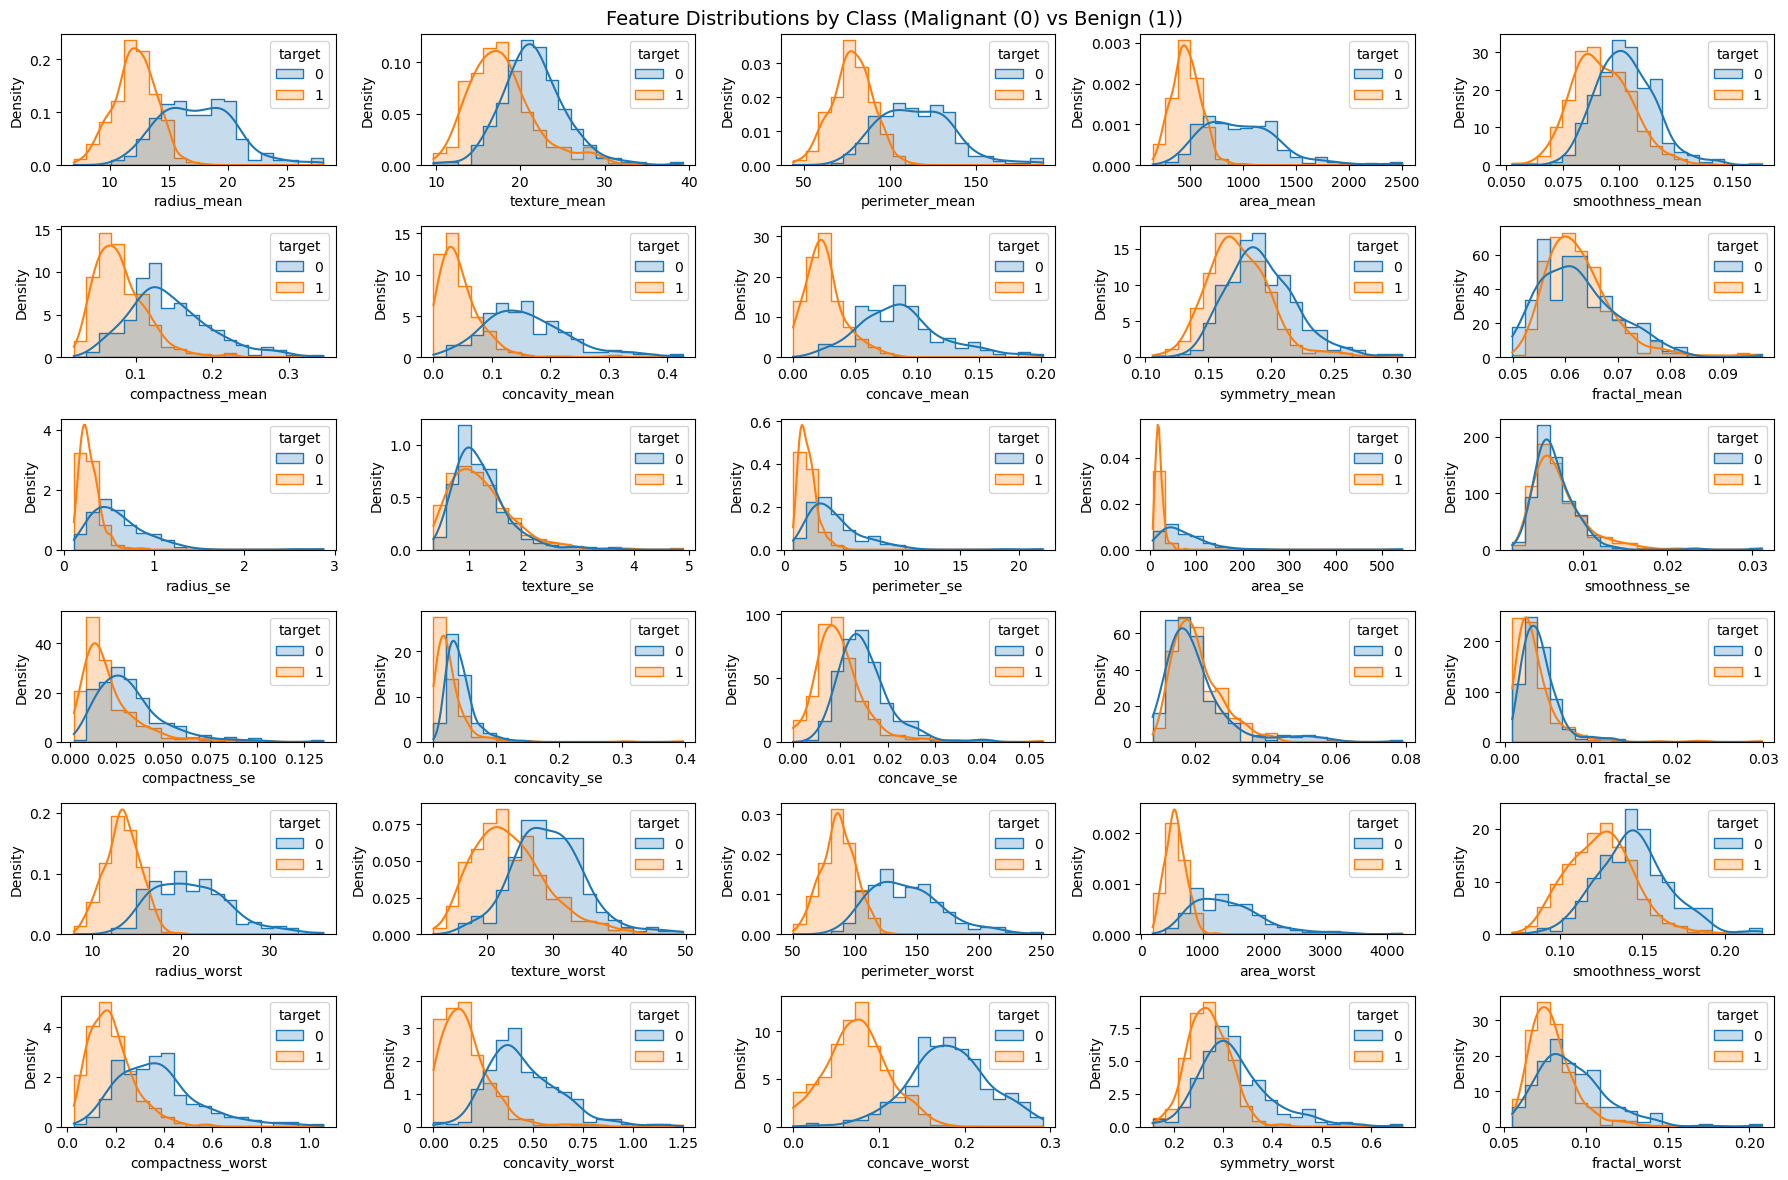

In [10]:
# Add target variable to DataFrame
df["target"] = data.target

# Features only
features = df.drop("target", axis=1)

# Create subplots grid
fig, axs = plt.subplots(6, 5, figsize=(18, 12))
axs = axs.ravel()

# Plot each feature with class separation
for i, col in enumerate(features.columns):
    sns.histplot(
        data=df,
        x=col,
        hue="target",
        kde=True,
        bins=20,
        ax=axs[i],
        element="step",
        stat="density",
        common_norm=False,
    )

# Remove unused subplots (if any)
for j in range(len(features.columns), len(axs)):
    fig.delaxes(axs[j])

plt.suptitle(
    "Feature Distributions by Class (Malignant (0) vs Benign (1))", fontsize=14
)
plt.tight_layout()
plt.savefig("figures/task1_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

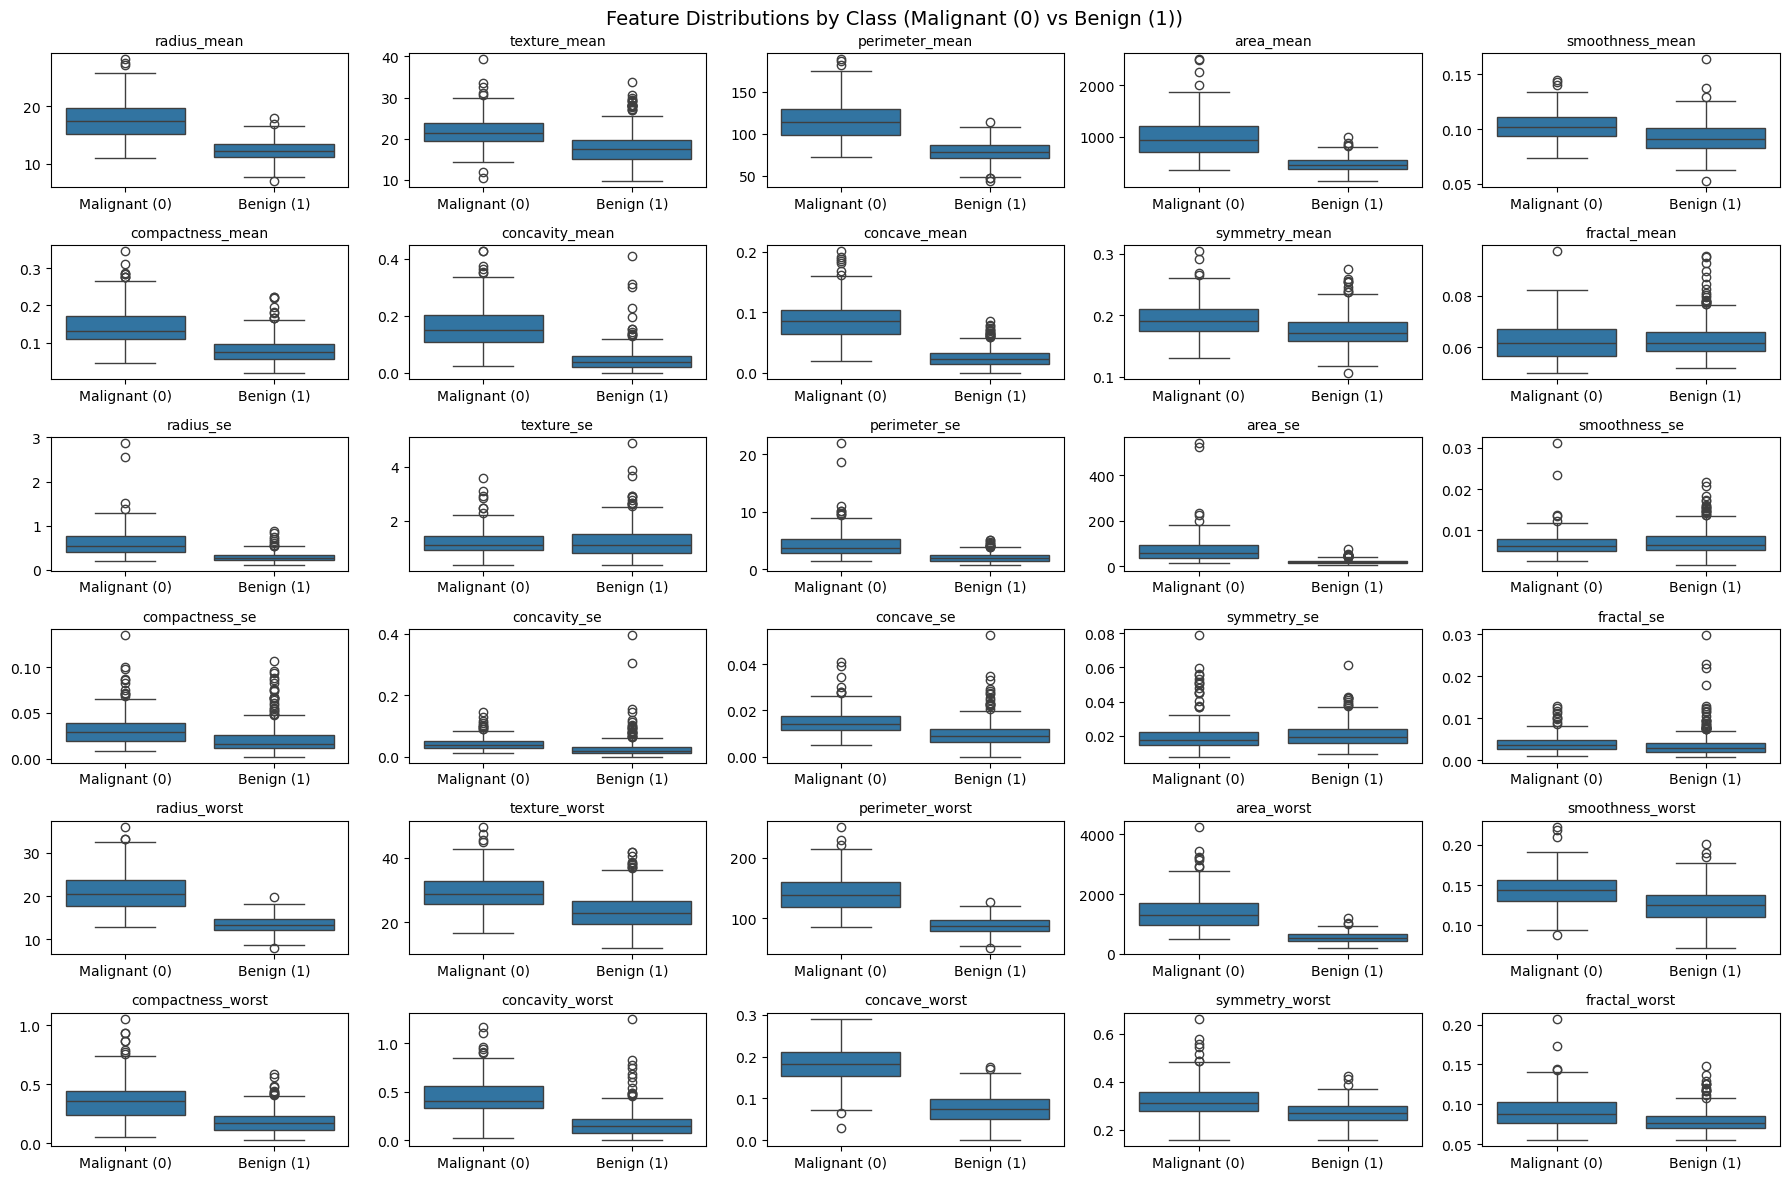

In [11]:
# Create subplot grid
fig, axs = plt.subplots(6, 5, figsize=(18, 12))
axs = axs.ravel()

# Plot boxplots for each feature
for i, col in enumerate(df.drop("target", axis=1).columns):
    sns.boxplot(data=df, x="target", y=col, ax=axs[i])

    axs[i].set_title(col, fontsize=10)
    axs[i].set_xlabel("")
    axs[i].set_ylabel("")

    # Rename x-axis labels
    axs[i].set_xticks([0, 1])
    axs[i].set_xticklabels(["Malignant (0)", "Benign (1)"])

# Remove unused subplots if any
for j in range(len(df.drop("target", axis=1).columns), len(axs)):
    fig.delaxes(axs[j])

plt.suptitle(
    "Feature Distributions by Class (Malignant (0) vs Benign (1))", fontsize=14
)

plt.tight_layout()
plt.savefig("figures/task1_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Looking at the distributions, we can see that some features show strong visual separation between classes, particularly those related to size and shape, such as ``radius``, ``perimeter``, ``area``. In these cases, malignant tumors tend to have higher values and broader distributions compared to benign tumors.

However, features such as ``texture``, ``smothness``, ``symmetry``, and ``fractal`` show substantial overlap between the two classes, suggesting they are less individually discriminative.

- **Plot a correlation heatmap of all features. Identify and discuss the top correlated pairs**

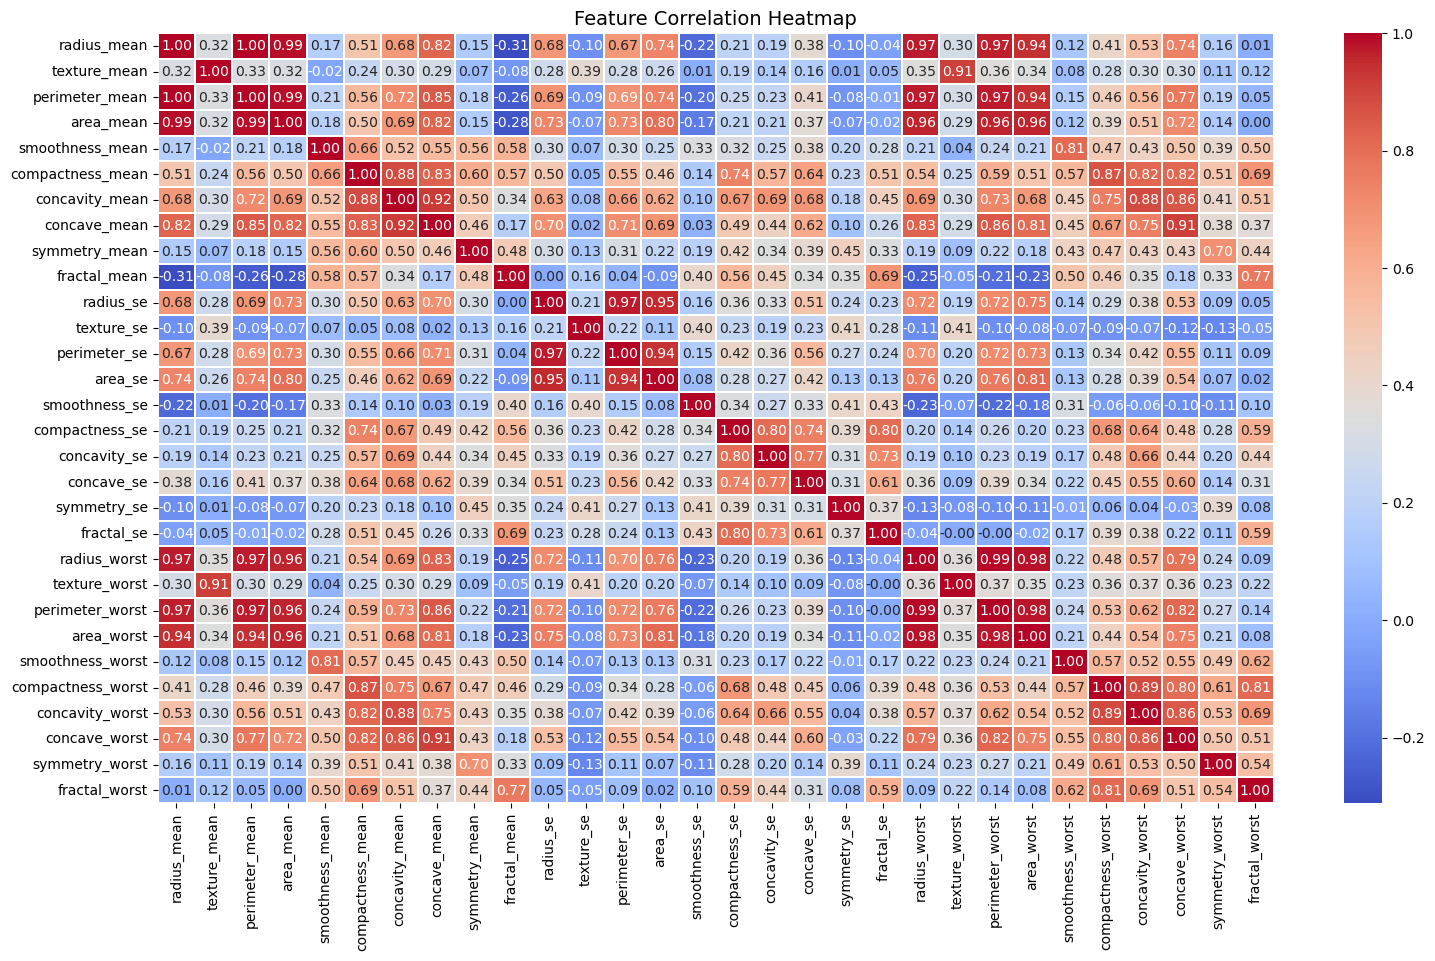

In [12]:
# Correlation matrix
corr = df.drop("target", axis=1).corr()

# Plot
plt.figure(figsize=(18, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.2)

plt.title("Feature Correlation Heatmap", fontsize=14)
plt.savefig("figures/task1_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

The correlation heatmap reveals strong multicollinearity among several feature groups, particularly those related to tumor size. Features such as ``radius_mean``, ``perimeter_mean``, and ``area_mean`` are almost perfectly correlated with each other, indicating that they capture very similar information about the tumor. A similar pattern is observed among the corresponding “worst” features (``radius_worst``, ``perimeter_worst``, ``area_worst``), which are also highly correlated. 

Additionally, mean features are strongly correlated with their respective worst values, suggesting redundancy across measurement scales.

In contrast, features such as texture and fractal dimension show weaker correlations with size-related features, indicating that they capture different aspects of tumor structure.

Overall, the dataset exhibits significant multicollinearity, meaning many features are redundant.

- **Keep the target column separate throughout. Do not use it during modelling.**

In [13]:
# Keep the target column separate
X = df.drop("target", axis=1)
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


<a id='section32'></a>
### **Task 2 - Preprocessing & Feature Analysis**

- **Split the data into training (80%) and test (20%) sets. Use stratification to preserve class balance.**

Stratified sampling was used to preserve the original class proportions in both the training and test sets. This ensures that model evaluation remains representative of the overall dataset distribution.

In [14]:
# Data split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y,
)

# Print shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [15]:
# Check class distribution in train and test sets
print(
    "Train class distribution (%):\n",
    y_train.value_counts(normalize=True).sort_index() * 100,
)
print(
    "\nTest class distribution (%):\n",
    y_test.value_counts(normalize=True).sort_index() * 100,
)

Train class distribution (%):
 target
0    37.362637
1    62.637363
Name: proportion, dtype: float64

Test class distribution (%):
 target
0    36.842105
1    63.157895
Name: proportion, dtype: float64


- **Apply ``StandardScaler`` to the features. Fit only on the training set.**

Standardisation was applied because several algorithms used in this project are sensitive to feature scale. 

Since the dataset contains variables measured on very different ranges, scaling ensures that all features contribute equally during model training.

In [16]:
# Initialize scaler
scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply same transformation to test data
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame
X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

- **Discuss whether any features should be dropped based on correlation or near-zero variance.**

As mentioned before, the correlation analysis shows that several features are highly correlated, particularly within the same measurement groups. For example, ``radius_mean``, ``perimeter_mean``, and ``area_mean`` (and their corresponding “worst” versions) exhibit very strong correlations. This indicates substantial redundancy, as these features capture similar information about tumor size.

From a modelling perspective, this level of multicollinearity can negatively impact linear models such as Logistic Regression. Therefore, it may be beneficial to drop one feature from each highly correlated group. However, Neural Networks are generally less sensitive to multicollinearity than linear models because they can learn complex internal representations. However, highly redundant features may still increase training complexity and reduce interpretability.

In [17]:
# Correlation Analysis (on unscaled training data)
corr_matrix = X_train.corr().abs()

# Upper triangle (to avoid duplicate pairs)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find all pairs with correlation > 0.90
high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "correlation"})
    .query("correlation > 0.90")
    .sort_values("correlation", ascending=False)
    .reset_index(drop=True)
)

print(f"Highly correlated pairs (> 0.90): {len(high_corr_pairs)}\n")
print(high_corr_pairs)

Highly correlated pairs (> 0.90): 21

          feature_1        feature_2  correlation
0       radius_mean   perimeter_mean     0.997789
1      radius_worst  perimeter_worst     0.993478
2       radius_mean        area_mean     0.988886
3    perimeter_mean        area_mean     0.987834
4      radius_worst       area_worst     0.985890
5   perimeter_worst       area_worst     0.978738
6    perimeter_mean  perimeter_worst     0.970918
7         radius_se     perimeter_se     0.970870
8       radius_mean     radius_worst     0.970133
9    perimeter_mean     radius_worst     0.969674
10      radius_mean  perimeter_worst     0.965936
11        area_mean     radius_worst     0.962829
12        area_mean  perimeter_worst     0.959360
13        area_mean       area_worst     0.957080
14        radius_se          area_se     0.955456
15      radius_mean       area_worst     0.943351
16   perimeter_mean       area_worst     0.943063
17     perimeter_se          area_se     0.938875
18   concavi

For each pair of highly correlated features, one feature was removed based on its lower absolute correlation with the target variable. This ensures that redundant features are eliminated while retaining the most predictive variables.

In [18]:
# Correlation with target
corr_with_target = X_train.copy()
corr_with_target["target"] = y_train

corr_target = corr_with_target.corr()["target"].abs().sort_values(ascending=False)

# Decide which features to drop
dropped = set()
for _, row in high_corr_pairs.iterrows():
    f1, f2 = row["feature_1"], row["feature_2"]

    # Skip if already removed
    if f1 in dropped or f2 in dropped:
        continue
    # Keep feature more correlated with target
    if corr_target[f1] >= corr_target[f2]:
        dropped.add(f2)
    else:
        dropped.add(f1)

print(f"Features to drop: {len(sorted(dropped))}")
print(sorted(dropped))

Features to drop: 10
['area_mean', 'area_worst', 'concave_mean', 'concavity_mean', 'perimeter_mean', 'perimeter_se', 'radius_mean', 'radius_se', 'radius_worst', 'texture_mean']


In [19]:
# Reduced unscaled dataset
features_to_keep = [col for col in X_train.columns if col not in dropped]
X_train_reduced = X_train[features_to_keep].copy()
X_test_reduced = X_test[features_to_keep].copy()

print(f"Number of original features: {X_train.shape[1]}")
print(f"Number of features after reduction: {X_train_reduced.shape[1]}")
print(f"\nFeatures kept:\n{features_to_keep}")
print(f"\nFeatures dropped:\n{sorted(dropped)}")

Number of original features: 30
Number of features after reduction: 20

Features kept:
['smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_mean', 'texture_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_se', 'symmetry_se', 'fractal_se', 'texture_worst', 'perimeter_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_worst', 'symmetry_worst', 'fractal_worst']

Features dropped:
['area_mean', 'area_worst', 'concave_mean', 'concavity_mean', 'perimeter_mean', 'perimeter_se', 'radius_mean', 'radius_se', 'radius_worst', 'texture_mean']


After applying correlation-based feature selection on the training set, the number of features was reduced from 30 to 20. Features exhibiting high pairwise correlation (|r| > 0.90) were identified as redundant and were selectively removed based on their lower correlation with the target variable.

As a result, several highly redundant size-related features such as ``radius_mean``, ``perimeter_mean``, ``area_mean``, and their corresponding worst and standard error versions were removed. These variables carried overlapping information about tumour size and geometry. Similarly, some texture-related and concavity-related features were also excluded.

The retained feature set preserves a diverse representation of tumour characteristics, including smoothness, compactness, symmetry, fractal dimension, and selected worst-case and error-based measurements. 

In [20]:
# Scale the reduced feature set
scaler_reduced = StandardScaler()

# Fit on training data
X_train_scaled_reduced = pd.DataFrame(
    scaler_reduced.fit_transform(X_train_reduced),
    columns=features_to_keep,
    index=X_train.index,
)

# Apply same transformation to test data
X_test_scaled_reduced = pd.DataFrame(
    scaler_reduced.transform(X_test_reduced),
    columns=features_to_keep,
    index=X_test.index,
)

Two feature sets were created: a full 30-feature dataset and a reduced 20-feature dataset obtained by removing highly correlated variables. Both datasets were then standardised.

| Dataset | Samples | Features | Description |
|---|---|---|---|
| ``X_train_scaled``  | 455 | 30 | All original features, scaled |
| ``X_test_scaled`` | 114 | 30 | All original features, scaled |
| ``X_train_scaled_reduced`` | 455 | 20 | Correlated features removed, scaled |
| ``X_test_scaled_reduced`` | 114 | 20 | Correlated features removed, scaled |

For all subsequent modelling tasks (KNN, Logistic Regression, SVM, and Neural Network), the reduced feature set will be used exclusively. This decision ensures a fair and consistent comparison across models and reduces redundancy caused by highly correlated features. 

<a id='section33'></a>
### **Task 3 - K-Nearest Neighbours (KNN)**

- **Train KNN classifiers for k = 1 to 20. Record test accuracy for each k.**

Choosing the right k is critical to model performance. When k is lower, it usually suggests higher variance with lower bias, which could lead to underfitting. In the opposite case, high k values suggest lower variance and higher bias, which could lead to overfitting.

In [21]:
# k values to try
k_values = range(1, 21)
knn_accuracies = []

for k in k_values:  # looping over all k values
    knn_model = KNeighborsClassifier(n_neighbors=k)  # initialising knn
    knn_model.fit(X_train_scaled_reduced, y_train)  # fitting knn
    y_pred_knn = knn_model.predict(X_test_scaled_reduced)  # predicting
    acc = accuracy_score(y_test, y_pred_knn)  # test accuracy
    knn_accuracies.append(acc)  # saving it

- **Plot accuracy vs k and identify the optimal value.**

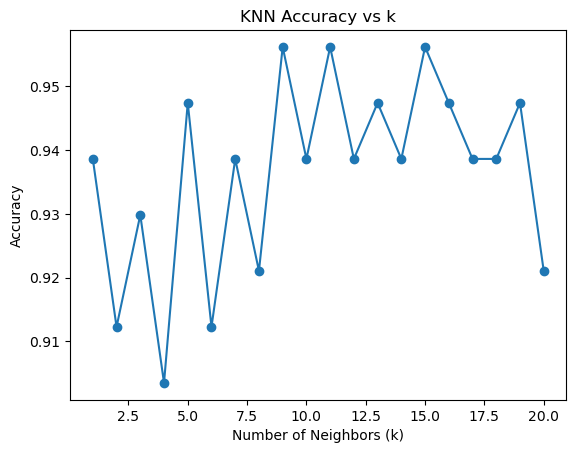

In [22]:
# Plotting accuracy vs k
plt.plot(k_values, knn_accuracies, marker="o")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs k")
plt.savefig("figures/task3_KNN.png", dpi=150, bbox_inches="tight")
plt.show()

We trained KNN for 1 to 20 neighbours and based on a k vs test accuracy plot, we found the optimal number of neighbours in this dataset using the elbow method.

- **Fit a final KNN model with the chosen k and print the classification report and confusion matrix.**

In [23]:
# Train KNN with best k (k=9)
start_time = time.time()

knn_model = KNeighborsClassifier(n_neighbors=9)

knn_model.fit(X_train_scaled_reduced, y_train)

knn_train_time = time.time() - start_time

print(f"KNN training time: {knn_train_time:.4f} seconds")

KNN training time: 0.0027 seconds


In [24]:
# cross-validation on the train dataset to further verify the results
knn_cv_scores = cross_val_score(knn_model, X_train_scaled_reduced, y_train, cv=5)
knn_cv_scores
print("KNN cv_scores mean: {} %".format(np.mean(knn_cv_scores) * 100))

KNN cv_scores mean: 94.5054945054945 %


In [25]:
# Evaluation on test set
y_pred_knn = knn_model.predict(X_test_scaled_reduced)
y_proba_knn = knn_model.predict_proba(X_test_scaled_reduced)[:, 1]

# Classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_knn))

Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.95      0.94        42
           1       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



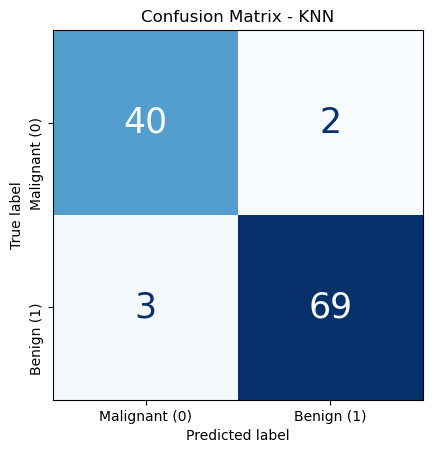

In [26]:
# Confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn, display_labels=["Malignant (0)", "Benign (1)"]
)
disp.plot(cmap="Blues", colorbar=False, text_kw={"fontsize": 25})
disp.ax_.tick_params(axis="y", labelrotation=90)
plt.title("Confusion Matrix - KNN")
plt.savefig("figures/task3_KNN_confusionmatrix.png", dpi=150, bbox_inches="tight")
plt.show()

Using this optimal value (k=9), we trained a KNN model, retrieving a precision of 93% in class 0 and 97% in class 1, and a recall of 95% in class 0 and 96% in class 1 on the test dataset. In total the model identified 40 true positives and 69 true negatives, together with 2 false negatives and 3 false positives

So far we found the optimal number of neighbours and then used cross-validation on that model. However, it would be even better to use cross-validation already when searching for the optimal number of neighbours. We will do exactly that using GridSearchCV.

In [27]:
knn2 = KNeighborsClassifier()  # initialising new KNN
knn_gscv = GridSearchCV(
    knn2, param_grid={"n_neighbors": np.arange(1, 21)}, cv=5
)  # using GridSearchCV to find the optimal number of neighbours using cross-validation
knn_gscv.fit(X_train_scaled_reduced, y_train)  # fitting
print(knn_gscv.best_params_)  # see best neighbour value
print((knn_gscv.best_score_) * 100)  # see the score of the best model

{'n_neighbors': np.int64(8)}
95.16483516483515


Now let's fit a model for 8 neighbours.

In [28]:
# Train KNN with best k (k=8)
start_time = time.time()

knn_model2 = KNeighborsClassifier(n_neighbors=8)
knn_model2.fit(X_train_scaled_reduced, y_train)

knn_train_time2 = time.time() - start_time

print(f"KNN2 training time: {knn_train_time2:.4f} seconds")

KNN2 training time: 0.0034 seconds


In [29]:
# cross-validation on the train dataset
knn_cv_scores2 = cross_val_score(knn_model2, X_train_scaled_reduced, y_train, cv=5)
knn_cv_scores2
print("KNN2 cv_scores mean: {} %".format(np.mean(knn_cv_scores2) * 100))

KNN2 cv_scores mean: 95.16483516483515 %


In [30]:
# Evaluation on test set
y_pred_knn2 = knn_model2.predict(X_test_scaled_reduced)
y_proba_knn2 = knn_model2.predict_proba(X_test_scaled_reduced)[:, 1]

# Classification report
print("Classification Report 2:\n")
print(classification_report(y_test, y_pred_knn2))

Classification Report 2:

              precision    recall  f1-score   support

           0       0.85      0.95      0.90        42
           1       0.97      0.90      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.93      0.92       114
weighted avg       0.93      0.92      0.92       114



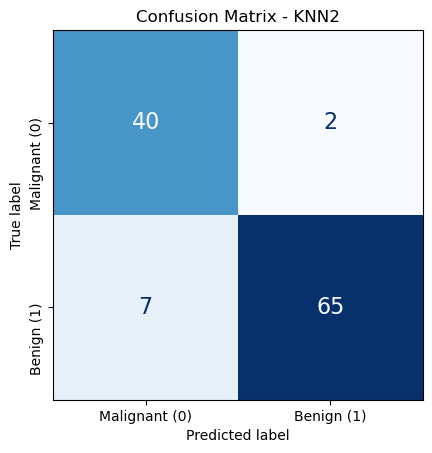

In [31]:
# Plot confusion matrix
cm_knn2 = confusion_matrix(y_test, y_pred_knn2)
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn2, display_labels=["Malignant (0)", "Benign (1)"]
)

disp2.plot(cmap="Blues", colorbar=False, text_kw={"fontsize": 16})
disp2.ax_.tick_params(axis="y", labelrotation=90)
plt.title("Confusion Matrix - KNN2")
plt.savefig("figures/task3_KNN2_confusionmatrix.png", dpi=150, bbox_inches="tight")
plt.show()

We see that this second KNN model (k=8) has more cases on the test dataset where the model predicts the label to be malignant, while the true label is benign. In a clinical setting, this type of error is less severe than classifying a malignant tumour as benign because in that case patients in need of treatment would be left without it due to incorrect predictions. But as this second model still gets more labels wrong, we will continue the rest of the analysis with the first KNN model using 9 neighbours.

<a id='section34'></a>
### **Task 4 - Logistic Regression**

- **Train Logistic Regression models sweeping the regularisation parameter C over at least 10 values (e.g. ``logspace(−3, 3, 10)``).**

In [32]:
# C values to try
values = np.logspace(-3, 3, 10)
logreg_accuracies = []

for C in values:
    logreg_model = LogisticRegression(C=C, max_iter=500)
    logreg_model.fit(X_train_scaled_reduced, y_train)
    y_pred_logreg = logreg_model.predict(X_test_scaled_reduced)
    acc = accuracy_score(y_test, y_pred_logreg)
    logreg_accuracies.append(acc)

- **Plot test accuracy vs C. Identify the optimal value.**

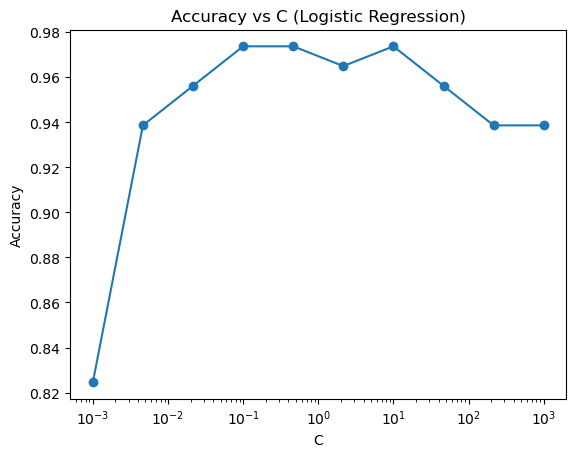

In [33]:
# Plot accuracy vs C
plt.plot(values, logreg_accuracies, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title("Accuracy vs C (Logistic Regression)")
plt.savefig("figures/task4_LogisticRegression.png", dpi=150, bbox_inches="tight")
plt.show()

Different values of the regularization parameter C were tested in order to optimize the Logistic Regression model. The results show that intermediate values of C achieve the best accuracies, while excessively low values worsen the model's performance

From the accuracy versus C plot, intermediate values of C achieved the best performance, with accuracy close to 97%.

In [34]:
param_grid = {"C": values}

grid = GridSearchCV(
    LogisticRegression(max_iter=500), param_grid, cv=5, scoring="accuracy"
)

grid.fit(X_train_scaled_reduced, y_train)

print("Best C:", grid.best_params_["C"])
print("Best CV accuracy:", grid.best_score_ * 100, "%")

best_C = grid.best_params_["C"]

Best C: 0.46415888336127775
Best CV accuracy: 97.36263736263737 %


To determine the most suitable value of the regularization parameter, a 5-fold cross-validation was carried out on the training set using GridSearchCV. The highest performance was obtained with C=0.46, achieving an average validation accuracy of approximately 97.4%

- **Fit a final model and print the classification report and confusion matrix.**

In [35]:
# Train Logistic Regression with best C
start_time = time.time()

logreg_model = LogisticRegression(C=best_C, max_iter=500)
logreg_model.fit(X_train_scaled_reduced, y_train)

logreg_train_time = time.time() - start_time

print(f"LogReg training time: {logreg_train_time:.4f} seconds")

LogReg training time: 0.0151 seconds


The final Logistic Regression model was trained using the optimal regularization parameter obtained through cross-validation (C= 0.46). The training process was efficient, requiring a short execution time.

In [36]:
# Evaluation on test set
y_pred_logreg = logreg_model.predict(X_test_scaled_reduced)
y_proba_logreg = logreg_model.predict_proba(X_test_scaled_reduced)[:, 1]

# Classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_logreg))

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



The classification report shows very high performance. The model achieved an overall accuracy of 97%, also obtaining high precision, recall, and F1-score values for both benign and malignant tumors

In [37]:
# Confusion matrix
cm_logreg = confusion_matrix(y_test, y_pred_logreg)
cm_logreg

array([[40,  2],
       [ 1, 71]])

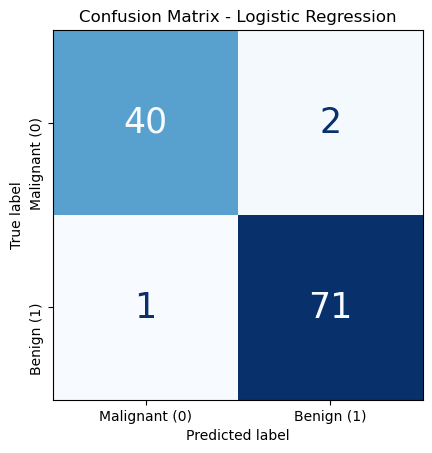

In [38]:
# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logreg, display_labels=["Malignant (0)", "Benign (1)"]
)

disp.plot(cmap="Blues", colorbar=False, text_kw={"fontsize": 25})
disp.ax_.tick_params(axis="y", labelrotation=90)
plt.title("Confusion Matrix - Logistic Regression")
plt.savefig("figures/task4_Logreg_confusionmatrix.png", dpi=150, bbox_inches="tight")
plt.show()

The confusion matrix shows that the model correctly classified 40 malignant tumors and 71 benign tumors, registering only 3 classification errors. Two malignant tumors were incorrectly identified as benign, while one benign tumor was classified as malignant. Overall, most samples were correctly identified, demonstrating that the model is capable of effectively distinguishing between malignant and benign tumors.


- **Inspect the learned coefficients. Which features carry the highest weights for predicting malignancy?**

In [39]:
# Coefficients of the logistic regression model
coef_df = pd.Series(
    logreg_model.coef_[0], index=X_train_scaled_reduced.columns
).sort_values(key=abs, ascending=False)

print(coef_df)

perimeter_worst     -2.009657
area_se             -1.953272
texture_worst       -1.229223
concave_worst       -1.076852
concavity_worst     -0.775990
fractal_mean         0.617831
concave_se          -0.561227
symmetry_worst      -0.535258
compactness_se       0.474091
smoothness_mean     -0.400531
fractal_se           0.265112
smoothness_se       -0.202960
smoothness_worst    -0.181026
symmetry_se          0.177820
symmetry_mean       -0.176695
concavity_se         0.174949
texture_se           0.170855
compactness_mean    -0.141268
compactness_worst   -0.056549
fractal_worst       -0.043306
dtype: float64


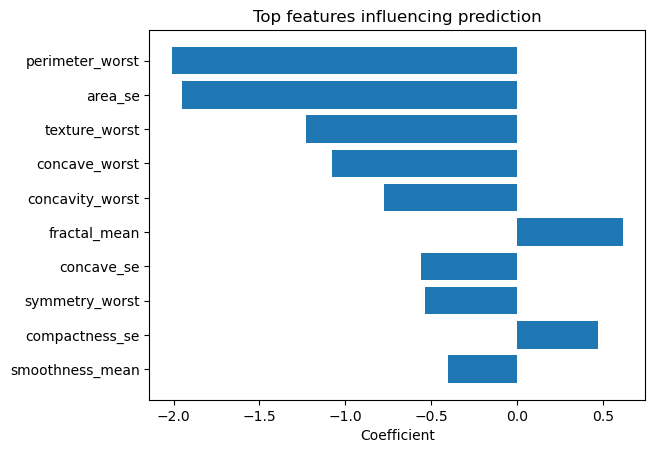

In [40]:
# Plot top 10 features
top10 = coef_df.head(10)

plt.barh(top10.index, top10.values)
plt.xlabel("Coefficient")
plt.title("Top features influencing prediction")
plt.gca().invert_yaxis()

plt.savefig("figures/task4_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

The analysis of the coefficients obtained by the model makes it possible to identify which variables have the greatest influence on the final prediction. Factors related to tumor size, texture, and shape (``perimeter_worst``, ``area_se``, ``concave_worst``, ``texture_worst``) show a particularly relevant contribution to the classification, being especially useful for identifying malignant tumors.

<a id='section35'></a>
### **Task 5 - Support Vector Machine (SVM)**

- **Train SVM classifiers with at least three kernels: linear, RBF, and polynomial.**

In [41]:
# Store results
svm_results = []

kernels = ["linear", "rbf", "poly"]

for kernel in kernels:
    svm_model = SVC(kernel=kernel, probability=True)

    start_time = time.time()
    svm_model.fit(X_train_scaled_reduced, y_train)
    training_time = time.time() - start_time

    y_pred_svm = svm_model.predict(X_test_scaled_reduced)
    acc = accuracy_score(y_test, y_pred_svm)

    svm_results.append(
        {"Kernel": kernel, "Accuracy": acc, "Training Time (s)": training_time}
    )

- **Report accuracy and training time for each kernel in a summary table.**

In [42]:
# Summary table
svm_results_df = pd.DataFrame(svm_results)
display(svm_results_df)

,Kernel,Accuracy,Training Time (s)
0,linear,0.964912,0.024746
1,rbf,0.973684,0.043002
2,poly,0.885965,0.037150


We can see that linear kernel works fast and achieves a high accuracy, suggesting the classes of the data might be linearly separable. RBF kernel obtains the highest accuracy which implies a better fit with a circular decision boundary. However, polynomial kernel, that can capture complex patterns, presents an accuracy of 89% and the fastest training time.

- **For the RBF kernel, explore the effect of C and gamma. Plot a small grid of results.**

Hyperparameter selection was performed using cross-validation to ensure an unbiased evaluation of the Support Vector Machine algorithm. Instead of tuning parameters like C and γ on the test set which would cause data leakage, we used GridSearchCV to search over values using only the training data. K-fold cross-validation evaluates each configuration across multiple splits, providing a more robust estimate and reducing overfitting. In this case, each (C, γ) is averaged over 5 folds.

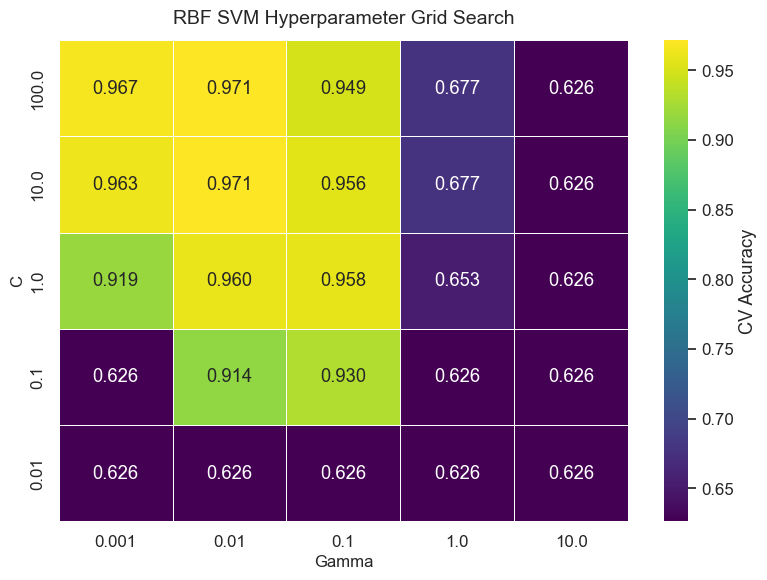

In [43]:
# Effect of hyperparameters on RBF SVM
C_values = [0.01, 0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1, 10]

param_grid = {"C": C_values, "gamma": gamma_values, "kernel": ["rbf"]}

# GridSearch with CV
grid = GridSearchCV(
    SVC(probability=True),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True,
)

grid.fit(X_train_scaled_reduced, y_train)

# Extract CV results into matrix form for heatmap
svm_cv_results = pd.DataFrame(grid.cv_results_)

accuracy_grid = svm_cv_results.pivot(
    index="param_C", columns="param_gamma", values="mean_test_score"
)

# Styling
sns.set_theme(style="whitegrid", font_scale=1.1)

plt.figure(figsize=(8, 6))

ax = sns.heatmap(
    accuracy_grid.astype(float),
    annot=True,
    fmt=".3f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "CV Accuracy"},
)

ax.invert_yaxis()
ax.set_title("RBF SVM Hyperparameter Grid Search", fontsize=14, pad=12)
ax.set_xlabel("Gamma", fontsize=12)
ax.set_ylabel("C", fontsize=12)

plt.tight_layout()
plt.savefig("figures/task5_SVM_crossvalidation.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
# Best parameters from CV
print("Best parameters (CV):", grid.best_params_)
print("Best CV score:", grid.best_score_)

Best parameters (CV): {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV score: 0.9714285714285715


The heatmap shows that **gamma has the strongest impact on model performance**. When gamma is set to a low or moderate value (0.01–0.1), the SVM achieves high accuracy across most tested values of C (around 0.94–0.97). However, when gamma increases to 1.0 and 10.0, performance drops significantly (to ~0.63–0.70), regardless of the value of C. This indicates that high gamma leads to an overly complex decision boundary that overfits the training data and generalizes poorly to the test set. Therefore, selecting an appropriate gamma is critical, with lower values providing a better balance between flexibility and generalization.

The effect of **C is more gradual but still relevant**. Increasing C generally improves accuracy when gamma is well-chosen, as it reduces regularization and allows the model to fit the training data more closely, which decreases bias but may increase variance. For example, at gamma = 0.01, accuracy steadily increases from 0.939 to 0.974 as C rises from 0.1 to 10. However, when gamma is too high (gamma = 1.0), increasing C does not recover performance.

Overall, the best results are achieved with a combination of **low gamma (0.01) and higher C (10.0)**, highlighting the need to tune both parameters, with particular attention to gamma.

- **Fit a final SVM with your chosen kernel and settings. Print the classification report and confusion matrix.**

In [45]:
# Best model from CV
start_time = time.time()

svm_model = grid.best_estimator_
svm_model.fit(X_train_scaled_reduced, y_train)

svm_train_time = time.time() - start_time

print(f"SVM training time: {svm_train_time:.4f} seconds")

SVM training time: 0.0214 seconds


In [46]:
# Evaluation on test set
y_pred_svm = svm_model.predict(X_test_scaled_reduced)
y_proba_svm = svm_model.predict_proba(X_test_scaled_reduced)[:, 1]

# Classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_svm))

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [47]:
# Confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_svm

array([[40,  2],
       [ 1, 71]])

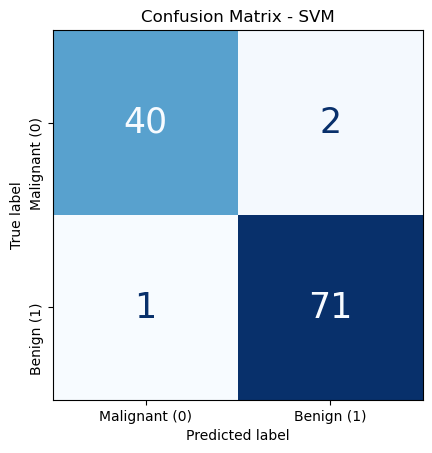

In [48]:
# Plot confusion matrix
plt.style.use("default")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm, display_labels=["Malignant (0)", "Benign (1)"]
)

disp.plot(cmap="Blues", colorbar=False, text_kw={"fontsize": 25})
disp.ax_.tick_params(axis="y", labelrotation=90)

plt.title("Confusion Matrix - SVM")
plt.savefig("figures/task5_SVM_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

The results indicate excellent overall performance, with an accuracy of 97% and strong balance between precision and recall across both classes. The confusion matrix shows that most predictions are correct, with only three total errors. Class 1 is identified particularly well, achieving a recall of 0.99, meaning almost all true instances are correctly detected. Class 0 has slightly lower recall (0.95), indicating a small tendency for the model to misclassify some of these instances as class 1. Overall, the classifier demonstrates strong generalization, minimal bias, and highly reliable predictions across both classes.

<a id='section36'></a>
### **Task 6 - Neural Network**

- **Use ``sklearn.neural_network.MLPClassifier`` to train a neural network.**

- **Experiment with at least two different hidden-layer architectures (e.g. (64,), (64, 32), (128, 64, 32)).**

In [49]:
architectures = [(32,), (64,), (16, 8), (32, 16), (64, 32), (64, 32, 16), (128, 64, 32)]

models = {}
scores = {}

for arch in architectures:
    mlp = MLPClassifier(
        hidden_layer_sizes=arch,
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    )

    mlp.fit(X_train_scaled_reduced, y_train)

    y_train_pred = mlp.predict(X_train_scaled_reduced)
    y_test_pred = mlp.predict(X_test_scaled_reduced)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    cv_score = cross_val_score(
        mlp, X_train_scaled_reduced, y_train, cv=5, scoring="accuracy"
    ).mean()

    print(f"Architecture {arch}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print(f"CV accuracy: {cv_score:.4f}")
    print("-" * 30)

    models[arch] = mlp
    scores[arch] = cv_score

Architecture (32,)
Train accuracy: 0.9495
Test accuracy: 0.9035
CV accuracy: 0.9187
------------------------------
Architecture (64,)
Train accuracy: 0.9736
Test accuracy: 0.9474
CV accuracy: 0.8923
------------------------------
Architecture (16, 8)
Train accuracy: 0.9385
Test accuracy: 0.8947
CV accuracy: 0.8967
------------------------------
Architecture (32, 16)
Train accuracy: 0.8945
Test accuracy: 0.8158
CV accuracy: 0.9253
------------------------------
Architecture (64, 32)
Train accuracy: 0.9714
Test accuracy: 0.9561
CV accuracy: 0.9341
------------------------------
Architecture (64, 32, 16)
Train accuracy: 0.9846
Test accuracy: 0.9474
CV accuracy: 0.9209
------------------------------
Architecture (128, 64, 32)
Train accuracy: 0.9648
Test accuracy: 0.9474
CV accuracy: 0.9692
------------------------------


In [50]:
best_2l_arch = (64, 32)
best_3l_arch = (128, 64, 32)
mlp_best_2l = models[best_2l_arch]
mlp_best_3l = models[best_3l_arch]

- We evaluated several neural network architectures, including (32,), (64,), (16, 8), (32, 16), (64, 32), (64,32,16) and (128, 64, 32). Although it would have been possible to use the full feature set, we chose to work with the reduced dataset (with highly correlated features removed) to remain consistent with the previous models, as established in Task 2.
- Based on the initial experiments, two candidate architectures were selected for deeper evaluation: the best-performing two-layer architecture (64, 32) and the best-performing three-layer architecture (128, 64, 32). These models were further compared using learning curves, cross-validation performance, and confusion-matrix analysis in order to evaluate not only predictive accuracy, but also model stability and generalization behaviour.

In [51]:
# additionally testing activations for 2 layers
activations = ["relu", "tanh", "logistic"]

print("Activation Function Comparison:")

for act in activations:
    mlp = MLPClassifier(
        hidden_layer_sizes=best_2l_arch,
        activation=act,
        # keep training conditions consistent
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    )

    mlp.fit(X_train_scaled_reduced, y_train)

    y_pred = mlp.predict(X_test_scaled_reduced)

    acc = accuracy_score(y_test, y_pred)
    print(f"{act:>8} -> Accuracy: {acc:.4f}")

Activation Function Comparison:
    relu -> Accuracy: 0.9561
    tanh -> Accuracy: 0.9211
logistic -> Accuracy: 0.9474


In [52]:
# additionally testing activations for 3 layers
activations = ["relu", "tanh", "logistic"]

print("Activation Function Comparison:")

for act in activations:
    mlp = MLPClassifier(
        hidden_layer_sizes=best_3l_arch,
        activation=act,
        # keep training conditions consistent
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    )

    mlp.fit(X_train_scaled_reduced, y_train)

    y_pred = mlp.predict(X_test_scaled_reduced)

    acc = accuracy_score(y_test, y_pred)
    print(f"{act:>8} -> Accuracy: {acc:.4f}")

Activation Function Comparison:
    relu -> Accuracy: 0.9474
    tanh -> Accuracy: 0.9737
logistic -> Accuracy: 0.9035


An additional experiment was conducted to evaluate the effect of different activation functions (ReLU, tanh, logistic). 
- The experiments also demonstrated the interaction between network architecture and activation functions. For the two-layer architecture (64, 32), the ReLU activation function achieved the best performance, while tanh resulted in lower predictive accuracy.
- Interestingly, for the deeper three-layer architecture (128, 64, 32), the tanh activation function produced the strongest results, outperforming both ReLU and logistic activation.

In [53]:
start_time = time.time()

mlp_best_model_2l = MLPClassifier(
    hidden_layer_sizes=best_2l_arch,
    activation="relu",
    solver="adam",
    alpha=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)

mlp_best_model_2l.fit(X_train_scaled_reduced, y_train)

mlp_train_time = time.time() - start_time

print(f"Neural Network training time: {mlp_train_time:.4f} seconds")

Neural Network training time: 0.2360 seconds


In [54]:
start_time = time.time()

mlp_best_arch = (128, 64, 32)

mlp_best_model = MLPClassifier(
    hidden_layer_sizes=mlp_best_arch,
    activation="tanh",
    solver="adam",
    alpha=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)

mlp_best_model.fit(X_train_scaled_reduced, y_train)

mlp_train_time = time.time() - start_time

print(f"Neural Network training time: {mlp_train_time:.4f} seconds")

Neural Network training time: 0.3129 seconds


Although the deeper architecture (128, 64, 32) achieved slightly better evaluation results overall, the simpler architecture (64, 32) required substantially less training time compared to (128, 64, 32). This demonstrates the trade-off between predictive performance and computational efficiency, as the smaller network achieved very competitive results while being considerably faster to train.

In [55]:
# Effect of L2 regularization (alpha) - 2 layers

alphas = [0.0001, 0.001, 0.01, 0.1]

train_scores = []
test_scores = []

for alpha in alphas:
    model_alpha = MLPClassifier(
        hidden_layer_sizes=best_3l_arch,  # or best_2l_arch depending on which one we want to test
        activation="tanh",  # or relu if doing for 2 layers
        solver="adam",
        alpha=alpha,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    )

    model_alpha.fit(X_train_scaled_reduced, y_train)

    y_train_pred = model_alpha.predict(X_train_scaled_reduced)
    y_test_pred = model_alpha.predict(X_test_scaled_reduced)

    train_scores.append(accuracy_score(y_train, y_train_pred))

    test_scores.append(accuracy_score(y_test, y_test_pred))

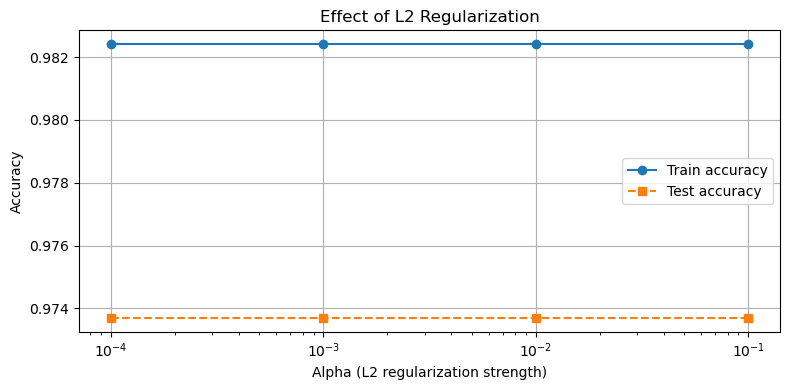

In [56]:
plt.figure(figsize=(8, 4))

plt.semilogx(alphas, train_scores, "o-", label="Train accuracy")
plt.semilogx(alphas, test_scores, "s--", label="Test accuracy")

plt.xlabel("Alpha (L2 regularization strength)")
plt.ylabel("Accuracy")

plt.title("Effect of L2 Regularization")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

- The regularization experiments were performed for both the selected two-layer and three-layer neural-network architectures. In both cases, the training and test accuracy scores remained relatively close across different alpha values, indicating good generalization performance and limited overfitting.
- For the two-layer architecture, stronger regularization slightly reduced performance, suggesting mild underfitting when the model was constrained too heavily. Interestingly, the deeper three-layer architecture also remained stable across different regularization strengths, despite its increased complexity.
- These results are important because overfitting was one of the main concerns when training larger neural networks. The combination of early stopping, validation monitoring, and L2 regularization appears to have successfully controlled model complexity and prevented excessive memorization of the training data.

- **Plot training and validation loss curves per epoch for your final model (use ``loss_curve_``).**

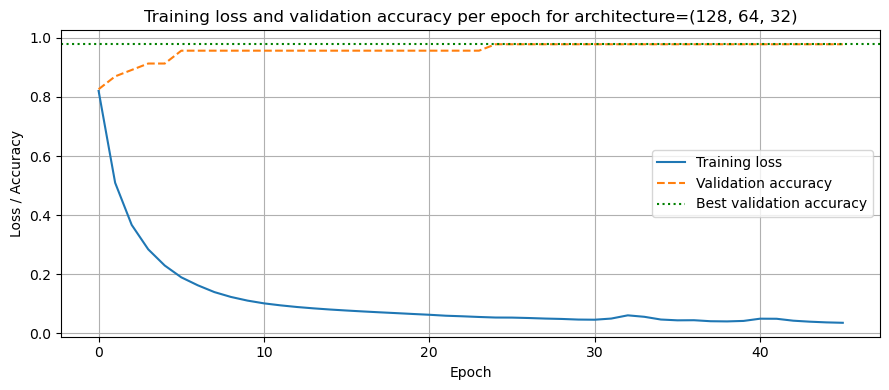

In [57]:
plt.figure(figsize=(9, 4))

plt.plot(mlp_best_model.loss_curve_, label="Training loss")
plt.plot(mlp_best_model.validation_scores_, label="Validation accuracy", linestyle="--")
plt.axhline(
    mlp_best_model.best_validation_score_,
    color="green",
    linestyle=":",
    label="Best validation accuracy",
)

plt.xlabel("Epoch")
plt.ylabel("Loss / Accuracy")

plt.title(
    f"Training loss and validation accuracy per epoch for architecture={mlp_best_arch}"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/task6_MLP_final_model.png", dpi=150, bbox_inches="tight")
plt.show()

- The graph shows that the neural network learned the training data successfully. The training loss steadily decreases during training, while the validation accuracy quickly improves and stays high throughout the epochs.
- Most importantly, the model shows limited signs of overfitting. Even though the selected architecture is more complex, the validation performance remains stable and does not decrease over time. This suggests that early stopping and regularization helped the model generalize well to unseen data.

- **Print the classification report and confusion matrix for your best configuration.**

 Neural Network (Best Configuration) 
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



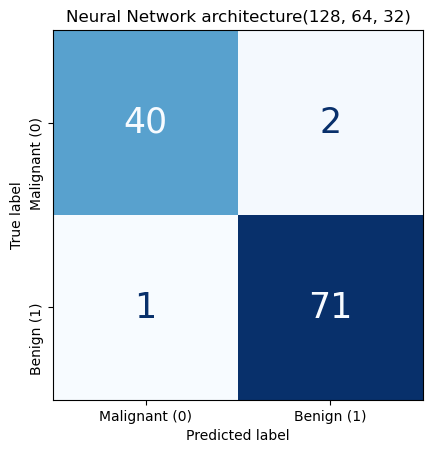

In [58]:
# Predict using best model
y_pred = mlp_best_model.predict(X_test_scaled_reduced)

# Classification report
print(" Neural Network (Best Configuration) ")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Malignant (0)", "Benign (1)"]
)
disp.plot(cmap="Blues", colorbar=False, text_kw={"fontsize": 25})
disp.ax_.tick_params(axis="y", labelrotation=90)
plt.title(f"Neural Network architecture{mlp_best_arch}")
plt.savefig("figures/task6_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

- The final neural network achieved very strong classification performance, with an overall accuracy of 97%. Most samples were classified correctly, and only a small number of misclassifications occurred.
- The confusion matrix shows that the model correctly identified most 0  and 1 cases, while only a few samples were predicted incorrectly. This indicates a good balance between precision and recall, which is especially important in medical classification tasks.
- Overall, the results suggest that the selected neural network generalizes well and provides reliable predictions on unseen data.

<a id='section37'></a>
### **Task 7 - Model Comparison & Evaluation**

- **Plot ROC curves for all five models on a single axes. Report the AUC for each.**

In [59]:
# All models
all_models = {
    "KNN": knn_model,
    "Logistic Regression": logreg_model,
    "SVM": grid.best_estimator_,
    "Neural Network": mlp_best_model,
}

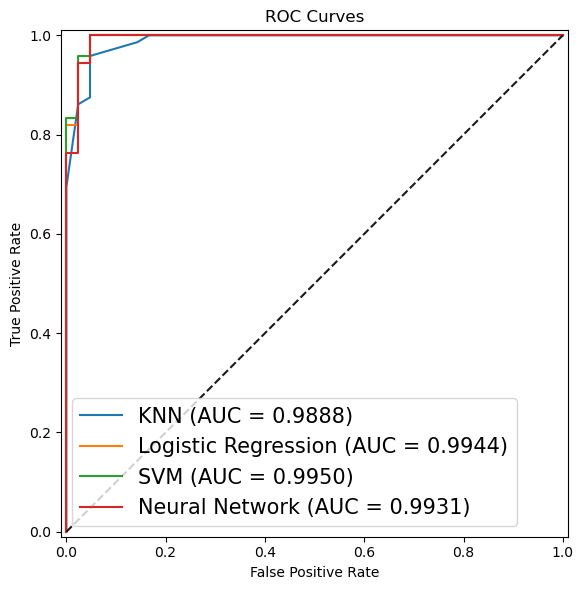

In [60]:
# Plot ROC curves for all models
summary = []

plt.figure(figsize=(8, 6))

train_times = {
    "KNN": knn_train_time,
    "Logistic Regression": logreg_train_time,
    "SVM": svm_train_time,
    "Neural Network": mlp_train_time,
}

for name, model in all_models.items():
    # Predictions
    y_pred = model.predict(X_test_scaled_reduced)

    # Scores for ROC/AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_scaled_reduced)[:, 1]
    else:
        y_score = model.decision_function(X_test_scaled_reduced)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    auc = roc_auc_score(y_test, y_score)

    # ROC curve
    RocCurveDisplay.from_predictions(
        y_test,
        y_score,
        curve_kwargs={"label": f"{name} (AUC = {auc:.4f})"},
        ax=plt.gca(),
    )

    summary.append(
        {
            "Model": name,
            "Accuracy": acc,
            "F1-score (macro)": f1,
            "AUC": auc,
            "Training Time (s)": train_times[name],
        }
    )

# Baseline diagonal
plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(fontsize=15)
plt.tight_layout()
plt.savefig("figures/task7_roc_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

- **Produce a summary table reporting Accuracy, F1-score (macro), AUC, and approximate training time for every model.**

In [61]:
# Create summary table
summary_table = pd.DataFrame(summary)

display(
    summary_table.style.format(
        {
            "Accuracy": "{:.4f}",
            "F1-score (macro)": "{:.4f}",
            "AUC": "{:.4f}",
            "Training Time (s)": "{:.4f}",
        }
    )
)

,Model,Accuracy,F1-score (macro),AUC,Training Time (s)
0,KNN,0.9561,0.9531,0.9888,0.0027
1,Logistic Regression,0.9737,0.9716,0.9944,0.0151
2,SVM,0.9737,0.9716,0.9950,0.0214
3,Neural Network,0.9737,0.9716,0.9931,0.3129


All models achieved strong classification performance. Although SVM achieved the highest AUC (0.995), differences between Logistic Regression, SVM, and the Neural Network were minimal, with all three reaching the same accuracy (0.974) and macro F1-score (0.972) 

- **Discuss which model you would deploy in a clinical setting and why - considering not just accuracy but also interpretability and compute cost.**

Among the evaluated models, SVM with RBF kernel achieved the highest predictive performance, particularly in terms of accuracy and AUC. However, when considering deployment in a real clinical setting, predictive performance alone is not sufficient. Interpretability, reliability, computational cost, and easy implementation are also important factors.

Although the Neural Network demonstrated strong classification performance, it behaves largely as a “black box”, making it difficult to interpret how predictions are generated. This lack of transparency can be problematic in healthcare environments, where clinicians often require understandable and explainable reasoning. In addition, Neural Networks generally require longer training times, more hyperparameter tuning, and greater computational resources compared to simpler models.

The SVM with RBF kernel also achieved excellent predictive results and strong generalisation performance. However, similar to Neural Networks, RBF SVMs are difficult to interpret because the decision boundary is highly non-linear and does not provide directly interpretable feature contributions. 

In contrast, Logistic Regression provides a strong balance between predictive performance, interpretability, and computational efficiency. 
Consequently, Logistic Regression would likely be the best model to deploy. It achieves the same predictive performance as the more complex models while remaining highly interpretable and computationally efficient. The learned coefficients can be directly inspected to understand which features contribute most strongly to malignancy prediction, making the model easier to validate clinically and communicate to healthcare professionals. In addition, its low training time reduces computational cost while maintaining excellent accuracy and AUC.